# Advertising Sales Prediction

EDA and a simple Multiple Linear Regression model using the advertising dataset.

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline

## Load and review the dataset

In [2]:
df = pd.read_csv("advertising.csv")
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
df.shape

(200, 4)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,15.1305,5.283892,1.6,11.000,16.00,19.050,27.0


## Data quality checks

In [6]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

The dataset has three advertising-spend features (`TV`, `Radio`, `Newspaper`) and one target (`Sales`). Check the results above for missing values and duplicate rows before modeling.

## Exploratory Data Analysis

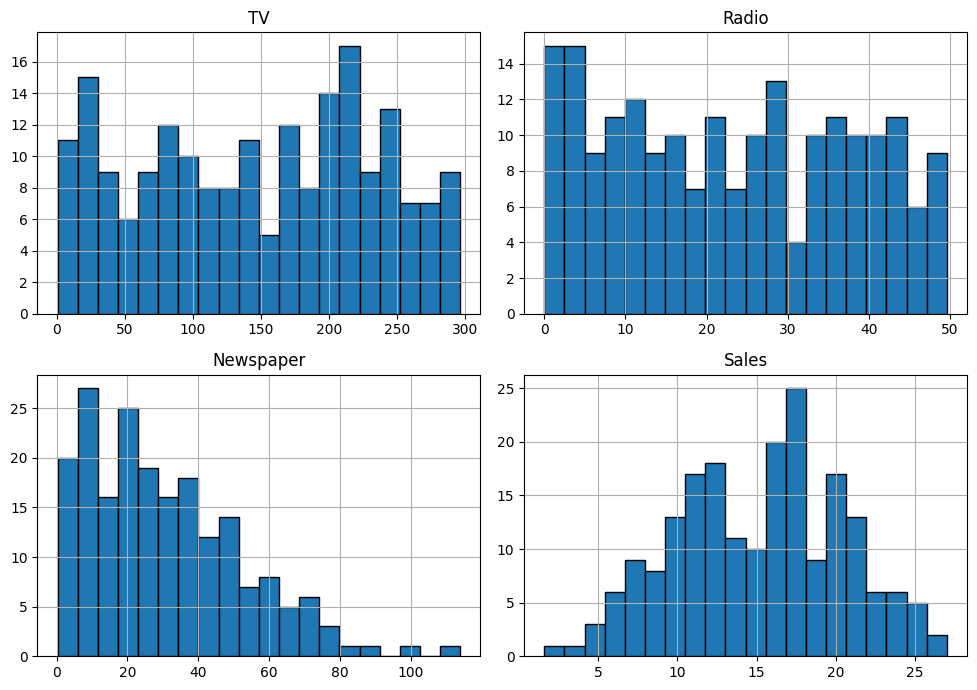

In [8]:
df.hist(figsize=(10, 7), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

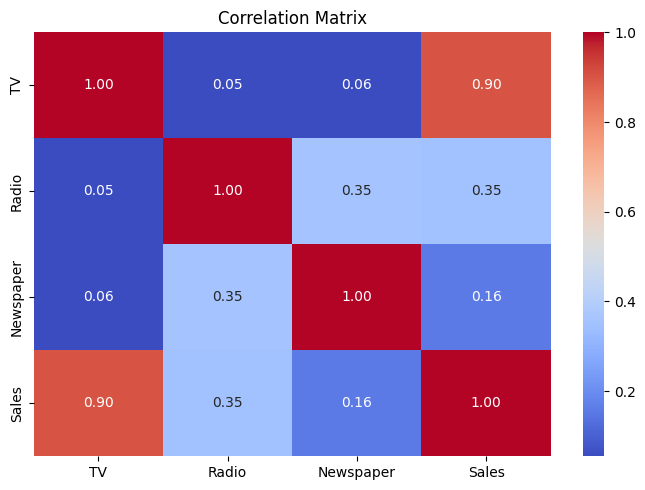

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

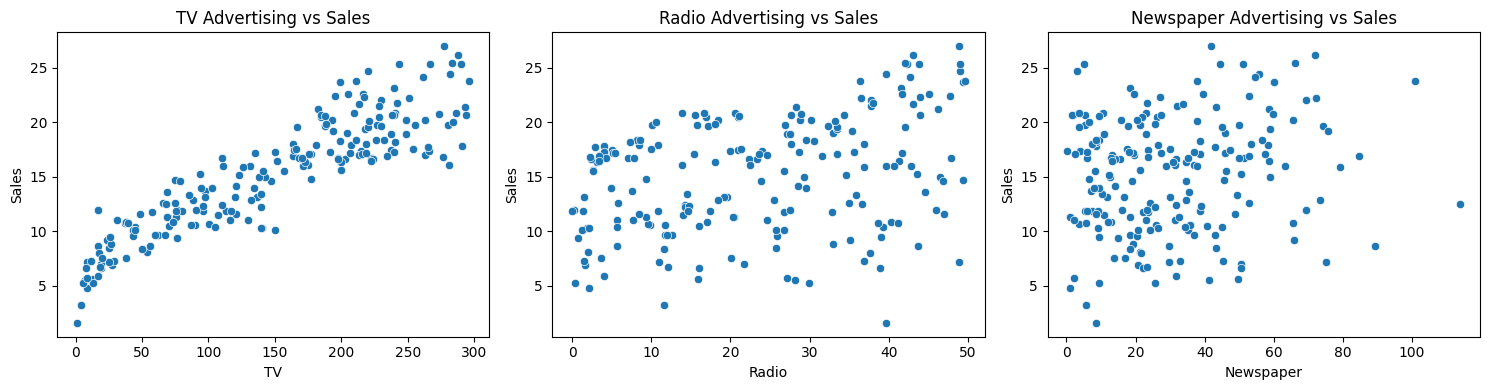

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    sns.scatterplot(data=df, x=col, y="Sales", ax=ax)
    ax.set_title(f"{col} Advertising vs Sales")
plt.tight_layout()
plt.show()

In [11]:
df.corr(numeric_only=True)["Sales"].sort_values(ascending=False)

Sales        1.000000
TV           0.901208
Radio        0.349631
Newspaper    0.157960
Name: Sales, dtype: float64

## Outlier check using the IQR method

The IQR method flags values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. The check below is applied to the input features only; unusually high values are reviewed rather than deleting rows.

In [12]:
outlier_summary = []

for col in ["TV", "Radio", "Newspaper"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    outlier_summary.append([col, Q1, Q3, lower_limit, upper_limit, count])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=["Feature", "Q1", "Q3", "Lower Limit", "Upper Limit", "Outlier Count"]
)
outlier_summary

,Feature,Q1,Q3,Lower Limit,Upper Limit,Outlier Count
0,TV,74.375,218.825,-142.300,435.500,0
1,Radio,9.975,36.525,-29.850,76.350,0
2,Newspaper,12.750,45.100,-35.775,93.625,2


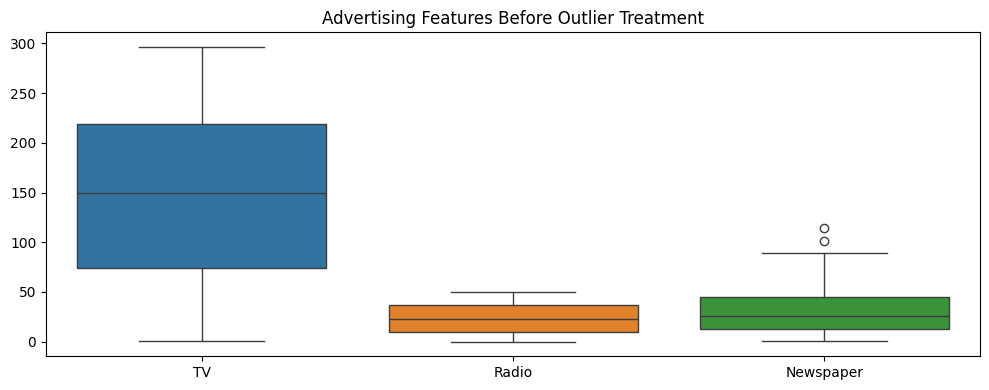

In [13]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[["TV", "Radio", "Newspaper"]])
plt.title("Advertising Features Before Outlier Treatment")
plt.tight_layout()
plt.show()

The IQR check identifies potential outliers, not necessarily errors. To keep all 200 observations, values outside the IQR limits are capped at the corresponding limit in the input features. The target (`Sales`) is not capped.

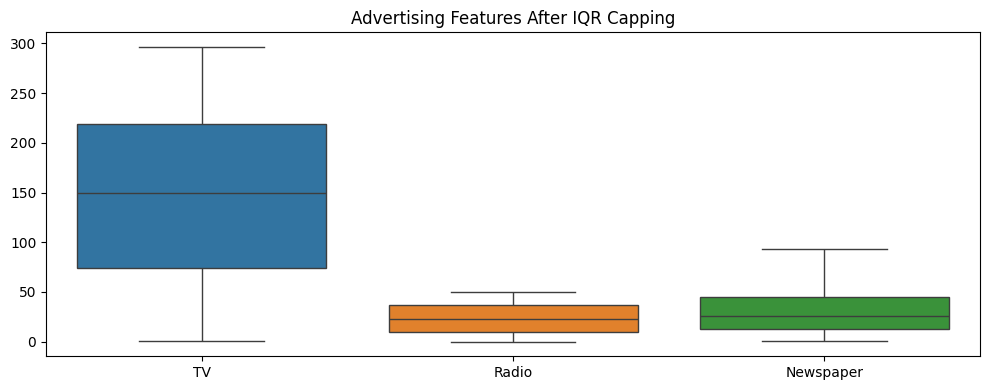

In [14]:
df_model = df.copy()

for col in ["TV", "Radio", "Newspaper"]:
    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df_model[col] = df_model[col].clip(lower=lower_limit, upper=upper_limit)

plt.figure(figsize=(10, 4))
sns.boxplot(data=df_model[["TV", "Radio", "Newspaper"]])
plt.title("Advertising Features After IQR Capping")
plt.tight_layout()
plt.show()

## Prepare the data and train the model

In [15]:
X = df_model[["TV", "Radio", "Newspaper"]]
y = df_model["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1
)

regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Model coefficients

In [16]:
print("Intercept:", round(regression_model.intercept_, 3))

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regression_model.coef_
})
coefficients

Intercept: 4.66


,Feature,Coefficient
0,TV,0.055021
1,Radio,0.102454
2,Newspaper,-0.001417


## Model evaluation

In [17]:
y_pred = regression_model.predict(X_test)

print("R²:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

R²: 0.907
MAE: 1.194
RMSE: 1.539


In [18]:
results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})
results.head(10)

,Actual Sales,Predicted Sales
0,23.8,21.287128
1,16.6,18.042093
2,11.9,10.058812
3,19.8,21.081756
4,17.6,20.764498
5,25.5,24.473649
6,16.9,16.807907
7,17.9,15.631939
8,10.5,10.126290
9,17.1,18.848223


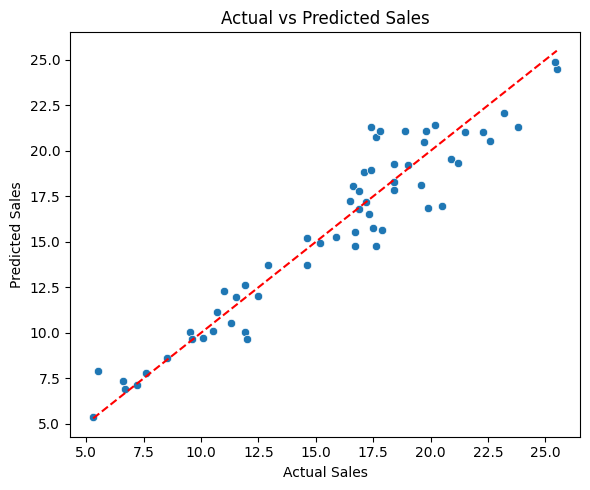

In [19]:
plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")
plt.tight_layout()
plt.show()

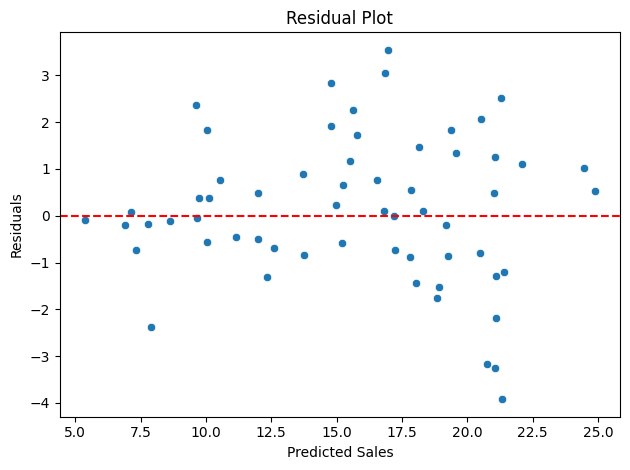

In [20]:
residuals = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

## Analysis

In [21]:
print("Rows:", len(df))
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Strongest feature correlation with Sales:")
print(df.corr(numeric_only=True)["Sales"].drop("Sales").sort_values(ascending=False).head(1))
print("\nTest-set R²:", round(r2_score(y_test, y_pred), 3))
print("Test-set MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("Test-set RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

Rows: 200
Missing values: 0
Duplicate rows: 0
Strongest feature correlation with Sales:
TV    0.901208
Name: Sales, dtype: float64

Test-set R²: 0.907
Test-set MAE: 1.194
Test-set RMSE: 1.539


## Conclusion

- Use the EDA plots and correlation values to identify which advertising channels have the strongest relationship with sales.
- IQR capping is used for input features to limit the influence of extreme values without removing rows. These values may still be valid observations.
- R² describes the share of test-set variation explained by the model; MAE and RMSE describe prediction error in the dataset's Sales units.
- This is a basic practice model. Results depend on the train-test split and do not establish that advertising spend alone causes sales changes.